# SuStaIn walkthrough: change the noise, see what survives
This notebook runs the same code as the terminal commands (`codes/run_analysis.py`), step by step, in memory.
The terminal entry point is `run_analysis.py`; this notebook is for exploring.

| Step | What happens | Paper analogue |
|---|---|---|
| 1 Simulate | 500 people (100 controls), 5 biomarkers, 2 hidden subtypes, each person has a hidden **subtype** and **stage** | 270 PPA patients + 121 controls |
| 2 z-score | express each biomarker as "SDs away from controls" | the *w-score* (Eq. 1) |
| 3 Fit | SuStaIn learns each subtype's **order of events** | Fig. 1 positional variance diagrams |
| 4 Read output | each person's most likely subtype + stage | Figs. 3 and 6 |
| 5 Compare with truth | only possible because the data are simulated | not possible in the real paper |

In [1]:
import tempfile
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
from IPython.display import Image
import make_synthetic_data as msd, preprocessing as prep, run_analysis as ra, plotting

# ======== THE ONE KNOB ========
NOISE = 1.0     # 1.0 = tutorial default. Try 0.5 (easier), 2.0 or 3.0 (harder)
# ==============================
SEED = 0

## 1. Simulate and look at the data
`noise=2` means the *same biology* with half the signal-to-noise: events sit at z = 0.5, 1, 1.5 instead of 1, 2, 3.

In [2]:
df, truth = msd.simulate(noise=NOISE, seed=SEED)
print(df.head(3).to_string())
print('true event order, subtype 0:', truth['gt_sequence'][0])
print('true event order, subtype 1:', truth['gt_sequence'][1])
print('event numbering:', truth['event_numbering'])

  subject_id    group  biomarker_0  biomarker_1  biomarker_2  biomarker_3  biomarker_4  true_subtype  true_stage
0      S0000  control       1.2997      -0.2621      -1.7225       1.6496      -0.0123          <NA>           0
1      S0001  control      -1.7177      -1.2444      -1.1873      -1.8105       2.3176          <NA>           0
2      S0002  control      -0.4314      -0.2307      -0.3011       1.5051      -1.7236          <NA>           0
true event order, subtype 0: [2, 4, 7, 3, 8, 12, 1, 13, 9, 6, 14, 11, 0, 5, 10]
true event order, subtype 1: [0, 1, 6, 5, 11, 10, 4, 3, 9, 2, 8, 7, 14, 13, 12]
event numbering: event = level_index * n_biomarkers + biomarker_index


In [3]:
cols = prep.biomarker_columns(df)
Z, info = prep.zscore_against_controls(df, cols)
ctrl, st, sb = (df.group == 'control').to_numpy(), df.true_stage.to_numpy(), df.true_subtype.fillna(0).astype(int).to_numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (i, j) in zip(ax, [(0, 1), (2, 3)]):
    a.scatter(Z[ctrl, i], Z[ctrl, j], c='lightgray', s=10, label='controls')
    for s, c in zip((0, 1), plotting.SUBTYPE_COLORS):
        m = ~ctrl & (sb == s); a.scatter(Z[m, i], Z[m, j], c=c, s=12, alpha=.7, label=f'true subtype {s}')
    a.set_xlabel(cols[i]); a.set_ylabel(cols[j])
ax[0].legend(fontsize=8); ax[0].set_title('SuStaIn never sees these colours'); plt.tight_layout()

## 2. Fit SuStaIn and read the output
Quick settings so this runs in about 2 minutes (the tutorial recommends 25 start points and 1e5+ MCMC iterations for real work).

In [4]:
work = Path(tempfile.mkdtemp())
r = ra.analyse(df, truth['z_levels'], truth['z_max'], work / 'fit', n_subtypes=2, max_subtypes=3,
               n_startpoints=5, n_mcmc=3000, seed=SEED, gt_sequence=np.array(truth['gt_sequence']))

In [5]:
e = r['truth_eval']
print(f"subtype accuracy {e['subtype_accuracy']:.1%} | mean stage error {e['stage_mae']:.2f} | event-order Spearman {np.round(e['sequence_spearman'], 2)}")
print('mean log-likelihood by number of subtypes:', {k: round(v) for k, v in r['metrics']['mean_mcmc_loglik'].items()})
r['table'].head()

subtype accuracy 90.8% | mean stage error 1.20 | event-order Spearman [0.98 0.97]
mean log-likelihood by number of subtypes: {'1': -4914, '2': -4480, '3': -4480}


,subject_id,group,subtype,prob_subtype,stage,prob_stage,subtypable,true_subtype,true_stage,subtype_correct
0,S0000,control,1,0.7047,0,0.3714,False,<NA>,0,<NA>
1,S0001,control,0,0.8830,0,0.5795,False,<NA>,0,<NA>
2,S0002,control,0,0.5409,0,0.3382,False,<NA>,0,<NA>
3,S0003,control,0,0.8919,0,0.3501,False,<NA>,0,<NA>
4,S0004,control,0,0.6326,0,0.3535,False,<NA>,0,<NA>


## 3. Positional variance diagrams (paper's Fig. 1 style)
Rows = biomarkers, columns = position in the sequence. **Gotcha:** `ml_subtype` is numbered by prevalence but `samples_sequence` is not; `ra.aligned()` re-orders it.

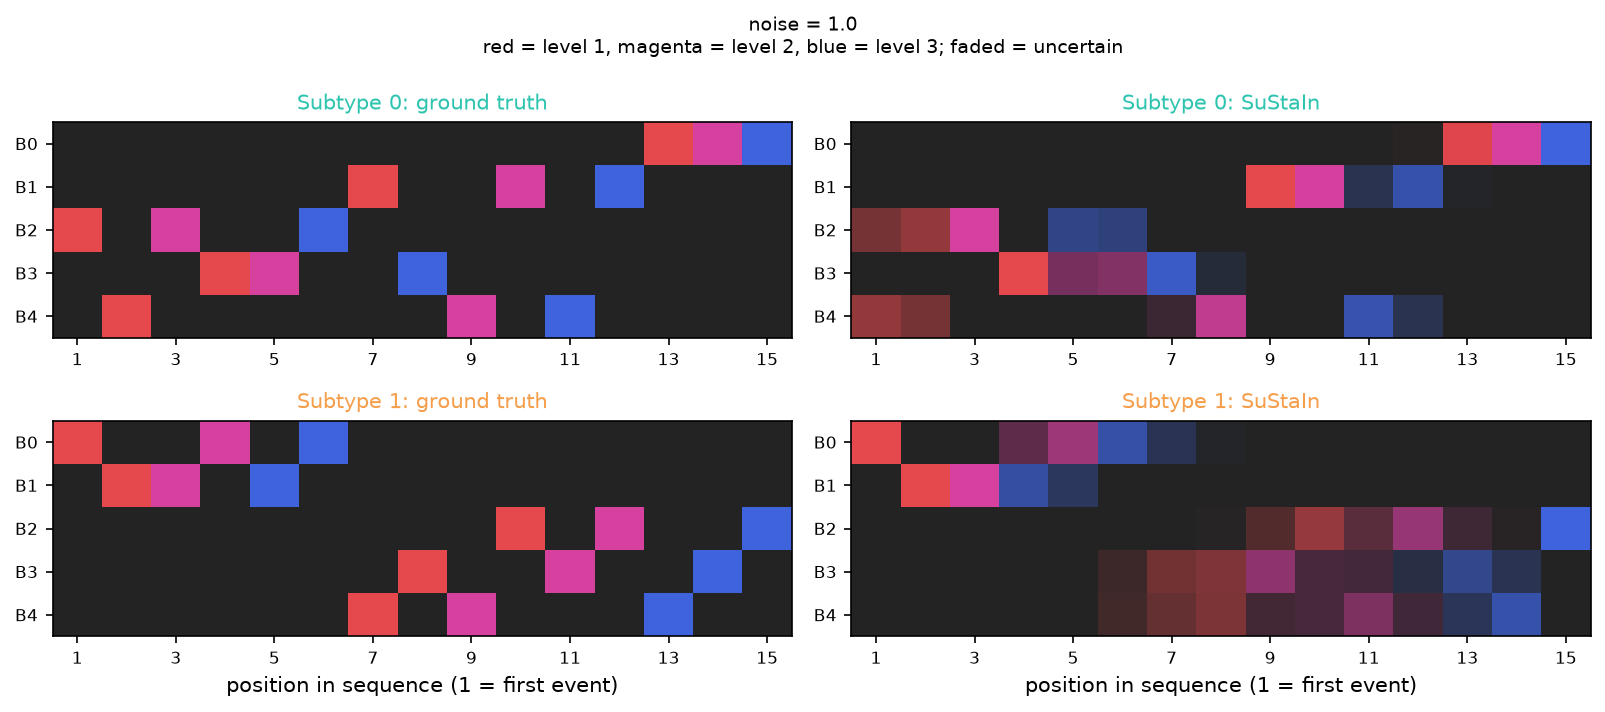

In [6]:
P_true = ra.truth_position_matrix(np.array(truth['gt_sequence']))
order = [e['mapping_true_to_model'][t] for t in range(2)]
plotting.positional_variance(r['P'], r['n_biomarkers'], r['n_levels'], work / 'pv.png', P_true=P_true[np.argsort(order)], title=f'noise = {NOISE}')
Image(work / 'pv.png')

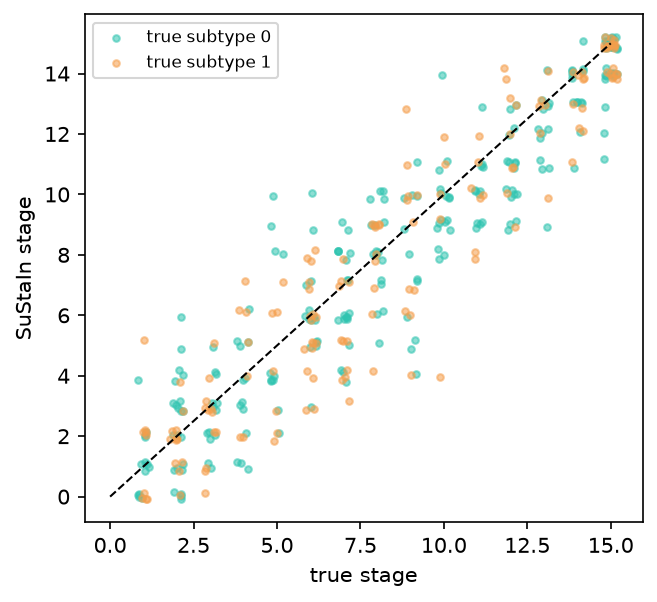

In [7]:
m = ~r['is_control']
plotting.stage_scatter(st[m], r['ml_stage'][m], sb[m], r['n_biomarkers'] * r['n_levels'], work / 'stage.png'); Image(work / 'stage.png')

## 4. The experiment: noise sweep
Precomputed with full settings by `codes/noise_sweep.py`.

In [8]:
import pandas as pd
pd.read_csv('../output/noise_sweep/summary.csv').round(3)

,noise,subtype_accuracy,stage_mae,sequence_rho_0,sequence_rho_1,mean_prob_subtype,patients_at_stage_0,mean_loglik_1_subtypes,mean_loglik_2_subtypes,mean_loglik_3_subtypes
0,0.5,0.962,0.690,0.996,0.982,0.976,11,-7182.165,-4929.472,-4924.905
1,1.0,0.908,1.182,0.986,0.979,0.926,14,-4913.731,-4480.710,-4483.015
2,1.5,0.835,1.692,0.979,0.968,0.862,20,-4377.577,-4236.148,-4236.725
3,2.0,0.772,2.140,0.943,0.900,0.802,26,-4131.157,-4073.453,-4076.145
4,3.0,0.715,2.930,0.900,0.793,0.727,38,-3902.658,-3885.922,-3888.473


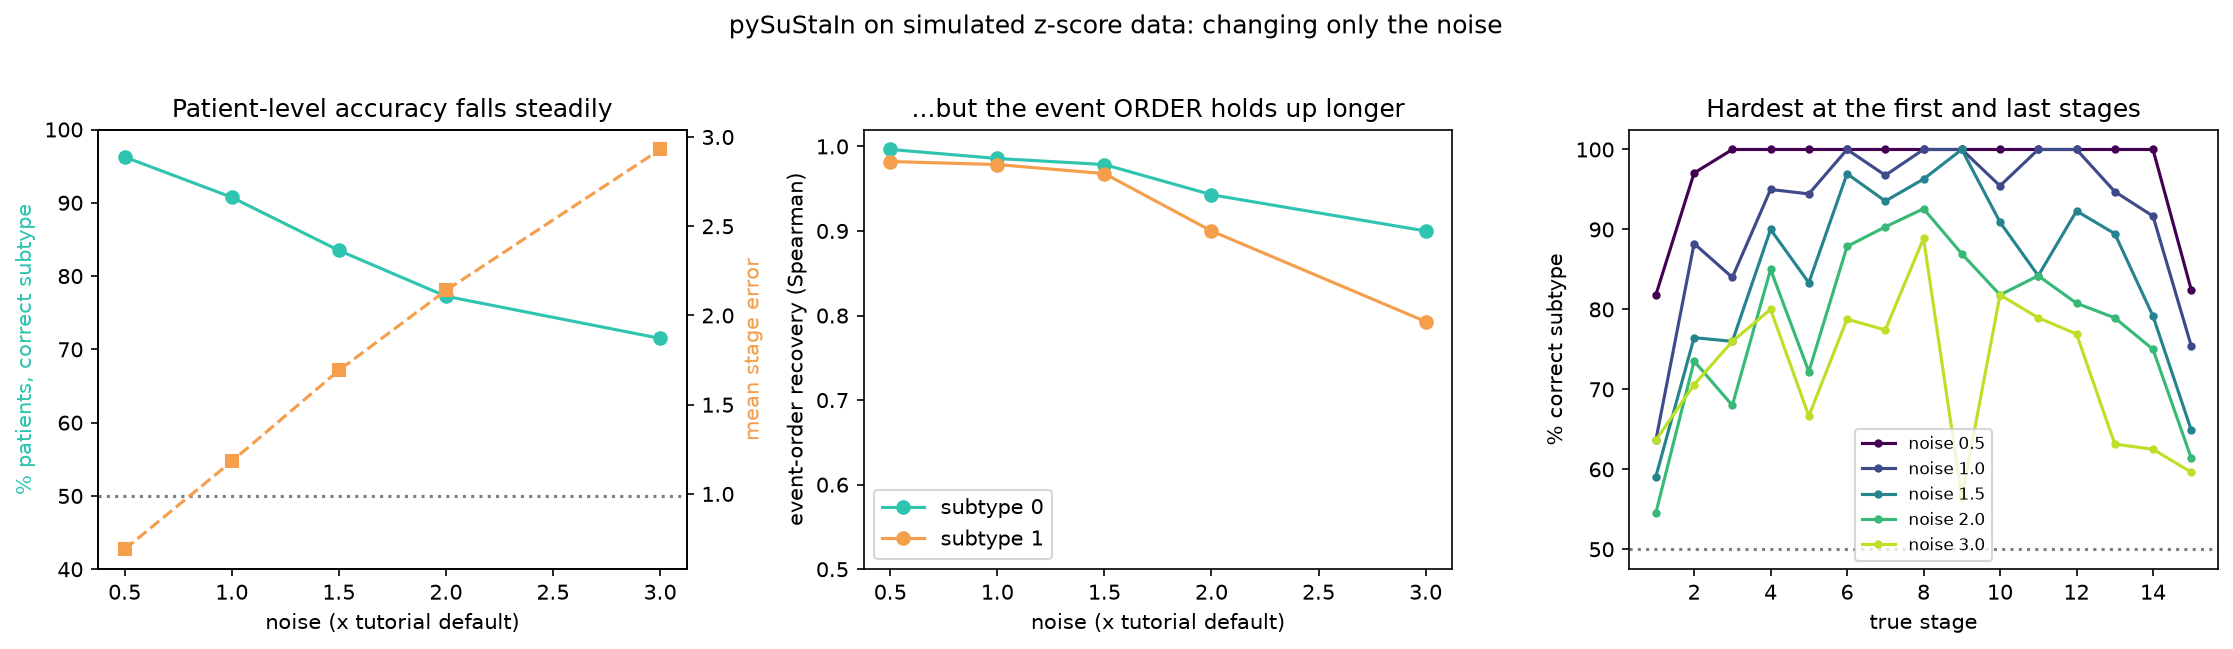

In [9]:
Image('../output/figures/noise_sweep.png')

## 5. What I took away
Researchers found four different patterns of brain shrinkage in a language-related dementia. Only one pattern clearly matched a diagnosis, and the others overlapped, so the current diagnosis labels don't tell the whole story.

**Question for the lab:** What would you want to see in a follow-up study to know whether these four subtypes are real, and not just a product of the algorithm?